# CHƯƠNG 5: MÔ HÌNH PHÂN TÍCH SỐNG SÓT


## 0. Khởi tạo

In [ ]:
import os, warnings, itertools, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.integrate import trapezoid
from lifelines import KaplanMeierFitter, NelsonAalenFitter, CoxPHFitter
from lifelines.statistics import proportional_hazard_test, multivariate_logrank_test, pairwise_logrank_test
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import sksurv
from sksurv.util import Surv
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored, cumulative_dynamic_auc, brier_score

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 9.5; plt.rcParams['figure.titlesize'] = 11

DATA_DIR = os.environ.get('DATA_DIR', '../Datasets')

A = pd.read_csv(os.path.join(DATA_DIR, 'group_a_survival.csv'), parse_dates=['install_date', 'first_active', 'last_active'])
B = pd.read_csv(os.path.join(DATA_DIR, 'group_b_landmark_survival.csv'), parse_dates=['install_date', 'first_active', 'last_active'])
COH = A[A.verified_new == 1].copy()
OLD = A[A.is_new == 0].copy()

# ---- Kiểm tra rò rỉ: cột doanh thu cả đời / cột ngày / first_open không được có trong file mô hình
LEAKY_COLS = {'ltv_revenue', 'has_spent', 'first_touch_date', 'first_open_date', 'has_first_open'}
assert LEAKY_COLS.isdisjoint(B.columns), f'File Nhóm B chứa cột rò rỉ: {sorted(LEAKY_COLS & set(B.columns))}'
assert {'ltv_revenue', 'has_spent'}.isdisjoint(A.columns), 'File Nhóm A chứa doanh thu cả đời'
_fc = os.path.join(DATA_DIR, 'feature_columns.csv')
FEATURE_WHITELIST = set(pd.read_csv(_fc).feature) if os.path.exists(_fc) else None

# ---- Tham số (có thể đổi bằng biến môi trường để chạy thử nhanh)
SEED = 42
N_REPEATS = int(os.environ.get('N_REPEATS', 10))        # số lần lặp 5-fold CV
MIN_AT_RISK, MIN_EVENTS_AFTER = 30, 10                   # điều kiện để báo cáo một mốc t
PENALIZER_FALLBACK = 0.01                                # CHỈ dùng khi Cox không phạt không hội tụ (có đếm)

print(f'Nạp dữ liệu thành công. Nhóm A: {len(A)} | Cohort verified: {len(COH)} | Cài cũ: {len(OLD)} | Nhóm B: {len(B)} ({int(B.event.sum())} sự kiện)')
print(f'Tham số: N_REPEATS={N_REPEATS}')


Nạp dữ liệu thành công. Nhóm A: 2056 | Cohort verified: 680 | Cài cũ: 1249 | Nhóm B: 129 (84 sự kiện)
Tham số: N_REPEATS=10, N_BOOT=1000, N_BOOT_AUC=500


## 5.1. Hazard theo thời gian (RQ5) và hàm sống sót (RQ1)

--- Hazard theo khoảng: Cohort verified (cài mới, không delayed entry) ---


,Độ dài (ngày),Người ở đầu khoảng,Người-ngày (Person-days),Sự kiện,Hazard rate (ngày⁻¹),CI thấp,CI cao
Khoảng (ngày),,,,,,,
"(0, 1]",1,680,680.0,378,0.5559,0.5012,0.6148
"(1, 3]",2,302,548.0,77,0.1405,0.1109,0.1756
"(3, 7]",4,223,803.0,45,0.0560,0.0409,0.0750
"(7, 14]",7,172,1043.0,37,0.0355,0.0250,0.0489
"(14, 30]",16,129,1529.0,50,0.0327,0.0243,0.0431
"(30, 60]",30,68,1287.0,25,0.0194,0.0126,0.0287
"(60, 114]",54,26,412.0,9,0.0218,0.0100,0.0415


,Độ dài (ngày),Người ở đầu khoảng,Người-ngày (Person-days),Sự kiện,Hazard rate (ngày⁻¹),CI thấp,CI cao
Khoảng (ngày),,,,,,,
"(0, 1]",1,807,807.0,378,0.4684,0.4224,0.5181
"(1, 3]",2,434,815.0,79,0.0969,0.0767,0.1208
"(3, 7]",4,356,1336.0,60,0.0449,0.0343,0.0578
"(7, 14]",7,309,2002.0,57,0.0285,0.0216,0.0369
"(14, 30]",16,274,3682.0,97,0.0263,0.0214,0.0321
"(30, 60]",30,201,5251.0,91,0.0173,0.0140,0.0213
"(60, 114]",54,163,8064.0,95,0.0118,0.0095,0.0144


Tỷ số hazard (0,1]/(30,60] = 28.7 lần | (0,1]/(60,114] = 25.5 lần


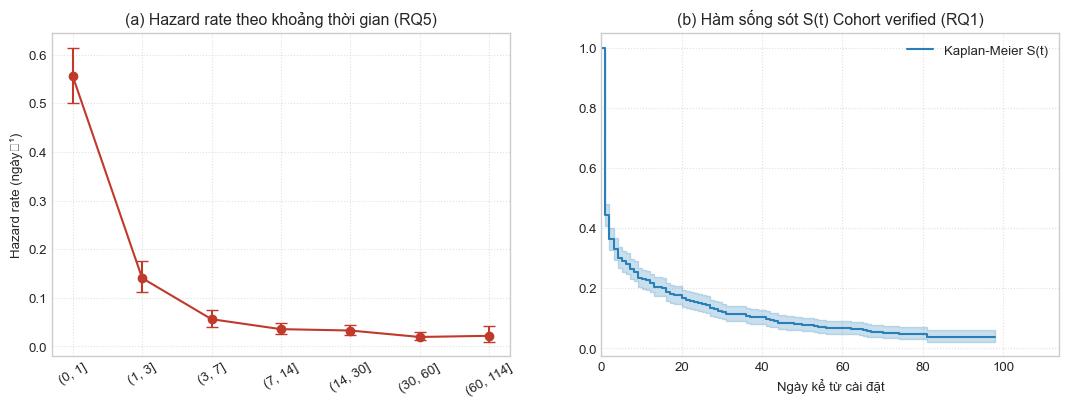

In [2]:
EDGES = [0, 1, 3, 7, 14, 30, 60, 114]

def interval_hazard(df, entry=True):
    rows = []
    ent = df.entry.values if entry else np.zeros(len(df))
    T = df['T'].values.astype(float)
    ev = df.event.values
    
    for a, b in zip(EDGES[:-1], EDGES[1:]):
        # Người còn trong risk set tại đầu khoảng a
        at_risk = (ent <= a) & (T > a)
        n_risk = int(at_risk.sum())
        # Số sự kiện xảy ra trong khoảng (a, b]
        d = int(((ev == 1) & (T > a) & (T <= b)).sum())
        expo = float(np.clip(np.minimum(T, b) - np.maximum(ent, a), 0, None).sum())

        # THỐNG NHẤT: Hazard rate = D / PT và CI Poisson cho TẤT CẢ các khoảng
        rate = d / expo if expo > 0 else np.nan
        lo = stats.chi2.ppf(.025, 2 * d) / (2 * expo) if expo > 0 and d > 0 else 0.0
        hi = stats.chi2.ppf(.975, 2 * d + 2) / (2 * expo) if expo > 0 else np.nan

        rows.append({
            'Khoảng (ngày)': f'({a}, {b}]',
            'Độ dài (ngày)': b - a,
            'Người ở đầu khoảng': n_risk,
            'Người-ngày (Person-days)': round(expo, 1), 
            'Sự kiện': d,
            'Hazard rate (ngày⁻¹)': round(rate, 4) if not np.isnan(rate) else np.nan,
            'CI thấp': round(lo, 4),
            'CI cao': round(hi, 4)
        })
    return pd.DataFrame(rows).set_index('Khoảng (ngày)')

print('--- Hazard theo khoảng: Cohort verified (cài mới, không delayed entry) ---')
hz_c = interval_hazard(COH, entry=False)
hz_a = interval_hazard(A, entry=True)
display(hz_c); display(hz_a)
r = hz_c['Hazard rate (ngày⁻¹)']
print(f"Tỷ số hazard (0,1]/(30,60] = {r.iloc[0]/r.loc['(30, 60]']:.1f} lần | (0,1]/(60,114] = {r.iloc[0]/r.loc['(60, 114]']:.1f} lần")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(hz_c))


ax[0].errorbar(x, hz_c['Hazard rate (ngày⁻¹)'], 
               yerr=[hz_c['Hazard rate (ngày⁻¹)'] - hz_c['CI thấp'], 
                     hz_c['CI cao'] - hz_c['Hazard rate (ngày⁻¹)']],
               fmt='-o', color='#c0392b', capsize=4, label='Cohort verified')

ax[0].set_xticks(x); ax[0].set_xticklabels(hz_c.index, rotation=30)
ax[0].set_title('(a) Hazard rate theo khoảng thời gian (RQ5)') 
ax[0].set_ylabel('Hazard rate (ngày⁻¹)') # Sửa nhãn trục y
ax[0].grid(True, linestyle=':', alpha=0.6)


km_c = KaplanMeierFitter().fit(COH['T'], COH.event, label='Kaplan-Meier S(t)')
km_c.plot_survival_function(ax=ax[1], color='#2980b9')
ax[1].set_xlim(0, 114); ax[1].set_title('(b) Hàm sống sót S(t) Cohort verified (RQ1)'); ax[1].set_xlabel('Ngày kể từ cài đặt')
ax[1].grid(True, linestyle=':', alpha=0.6)


## 5.2. Biến, VIF theo từng mô hình, kiểm tra tuyến tính

--- Ma trận tương quan Spearman giữa các biến đặc trưng Nhóm B ---


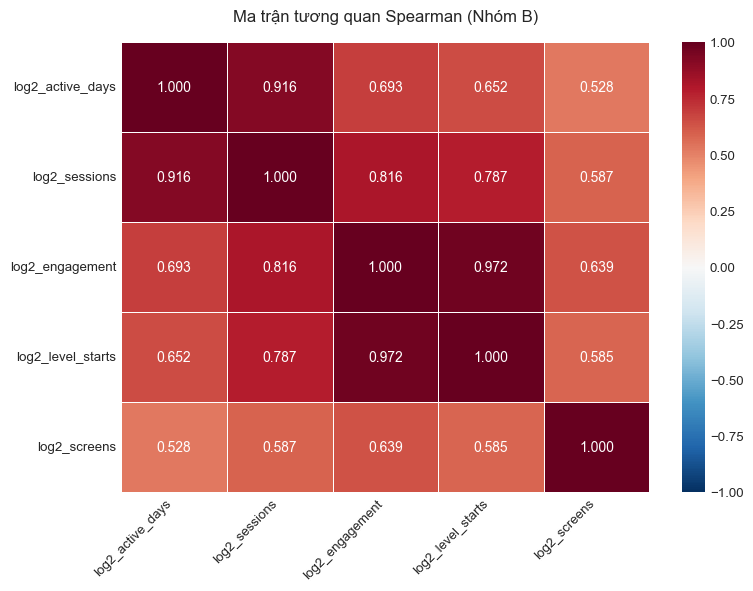

log2_screens: Spearman = 0.528 với active_days và 0.585 với level_starts.


,Mô hình,Đặc trưng,VIF,Vi phạm (>5)
0,M2_Behavior,log2_active_days,2.032,
1,M2_Behavior,log2_level_starts,2.183,
2,M2_Behavior,android,1.179,
3,M2_Behavior,plays_quickplay,1.271,
4,M2_Alt_Sessions,log2_active_days,6.498,CÓ
5,M2_Alt_Sessions,log2_sessions,6.817,CÓ
6,M2_Alt_Sessions,android,1.064,
7,M2_Alt_Sessions,plays_quickplay,1.264,
8,M3_Full,log2_active_days,2.142,
9,M3_Full,log2_level_starts,2.336,


CẢNH BÁO: M2_Alt_Sessions có VIF lớn nhất = 6.82 > 5 (mục 2.6.8) -> chỉ dùng làm độ nhạy, không dùng để kết luận.


In [3]:
def add_feats(d):
    d = d.copy()
    d['log2_active_days']   = np.log2(1 + d.active_days)
    d['log2_engagement']    = np.log2(1 + d.engagement_events)
    d['log2_sessions']      = np.log2(1 + d.session_count)
    d['log2_screens']       = np.log2(1 + d.distinct_screens)
    d['log2_level_starts']  = np.log2(1 + d.level_starts)
    d['android']            = (d.platform == 'ANDROID').astype(float)
    d['india']              = (d.country == 'India').astype(float)
    d['plays_quickplay']    = d.plays_quickplay.astype(float)
    return d

B = add_feats(B)

# Các cột gốc dùng làm đặc trưng phải nằm trong whitelist của notebook chuẩn bị
RAW_USED = {'active_days', 'engagement_events', 'session_count', 'distinct_screens', 'level_starts', 'platform', 'country',
            'plays_quickplay', 'no_level_start_14d', 'screen_views', 'level_completes', 'n_spend'}
if FEATURE_WHITELIST is not None:
    assert RAW_USED <= FEATURE_WHITELIST, f'Dùng cột ngoài whitelist: {sorted(RAW_USED - FEATURE_WHITELIST)}'

# ---- Định nghĩa các mô hình Cox (M3 ⊃ M2; ablation bỏ india / bỏ screens)
FEATS_M1 = ['engagement_segment']
FEATS_M2 = ['log2_active_days', 'log2_level_starts', 'android', 'plays_quickplay']
FEATS_M2_ALT = ['log2_active_days', 'log2_sessions', 'android', 'plays_quickplay']
FEATS_M3 = ['log2_active_days', 'log2_level_starts', 'log2_screens', 'android', 'india', 'plays_quickplay']
FEATS_M3_NOINDIA = [v for v in FEATS_M3 if v != 'india']
FEATS_M3_NOSCREENS = [v for v in FEATS_M3 if v != 'log2_screens']
COX_MODELS = {'M1_Segment': FEATS_M1, 'M2_Behavior': FEATS_M2, 'M2_Alt_Sessions': FEATS_M2_ALT, 'M3_Full': FEATS_M3,
              'M3_noIndia': FEATS_M3_NOINDIA, 'M3_noScreens': FEATS_M3_NOSCREENS}   # M3 bỏ cả hai = M2

# ---- Tương quan Spearman 
print('--- Ma trận tương quan Spearman giữa các biến đặc trưng Nhóm B ---')
sp_cols = ['log2_active_days', 'log2_sessions', 'log2_engagement', 'log2_level_starts', 'log2_screens']
sp_mat = B[sp_cols].corr(method='spearman').round(3)

plt.figure(figsize=(8, 6))
sns.heatmap(sp_mat, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt=".3f", 
            linewidths=0.5, annot_kws={"size": 10})
plt.title('Ma trận tương quan Spearman (Nhóm B)', fontsize=12, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"log2_screens: Spearman = {sp_mat.loc['log2_screens', 'log2_active_days']:.3f} với active_days và "
      f"{sp_mat.loc['log2_screens', 'log2_level_starts']:.3f} với level_starts.")

# ---- VIF theo từng mô hình + bảng ứng viên (giải thích lý do loại biến)
def vif_table(cols, name):
    X = add_constant(B[cols])
    return pd.DataFrame({'Mô hình': name, 'Đặc trưng': cols,
                         'VIF': [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]})
vif_sets = {k: v for k, v in COX_MODELS.items() if k != 'M1_Segment'}
vif_sets['Ứng viên (giải thích loại biến)'] = ['log2_active_days', 'log2_sessions', 'log2_engagement', 'log2_level_starts',
                                               'log2_screens', 'android', 'india', 'plays_quickplay']
vif_df = pd.concat([vif_table(v, k) for k, v in vif_sets.items()], ignore_index=True)
vif_df['VIF'] = vif_df.VIF.round(3); vif_df['Vi phạm (>5)'] = np.where(vif_df.VIF > 5, 'CÓ', '')
display(vif_df)

# Mô hình nào vi phạm VIF > 5 bị đánh dấu: chỉ là phân tích độ nhạy
VIF_MAX = vif_df[vif_df['Mô hình'].isin(COX_MODELS)].groupby('Mô hình').VIF.max().to_dict()
VIF_FLAG = {m: ('VI PHẠM VIF>5' if VIF_MAX.get(m, 0) > 5 else '') for m in COX_MODELS}
for m, f in VIF_FLAG.items():
    if f: print(f'CẢNH BÁO: {m} có VIF lớn nhất = {VIF_MAX[m]:.2f} > 5 (mục 2.6.8) -> chỉ dùng làm độ nhạy, không dùng để kết luận.')
if not any(VIF_FLAG.values()): print('Không mô hình nào vi phạm VIF > 5.')


## 5.3. Các mô hình Cox (suy diễn trên toàn Nhóm B, **không phạt**), kiểm định PH và tuyến tính

Gồm: bảng HR (không phạt), AIC, kiểm định tỷ số hợp lý cho các cặp lồng nhau, HR đơn biến so với đa biến, Schoenfeld (M1, M2, M2_Alt, M3; Holm trong từng mô hình) và kiểm tra tuyến tính bằng số hạng bậc hai.


In [4]:
# ===== Phân khúc: DÙNG ĐÚNG lớp Segmenter của notebook chuẩn bị (phân vị hạng trung bình) =====
SEG_METRICS = ['session_count', 'active_days', 'engagement_events']
SEG_LABELS = ['Very Low', 'Low', 'Moderate', 'Highly Engaged'] 
REF = 'Very Low'

class Segmenter:
    """Phân khúc tương tác. fit() trên TRAIN; transform() áp lên bất kỳ tập nào.
    Phân vị = (left + right + 1) / (2n): trùng khớp chính xác rank(pct=True, method='average') với giá trị trong train."""
    def fit(self, tr):
        act = tr[tr.no_level_start_14d == 0]
        self.m = {c: np.sort(act[c].values.astype(float)) for c in SEG_METRICS}
        self.comp = np.sort(self._comp(act)); return self
    @staticmethod
    def _pct(sorted_ref, v):
        return (np.searchsorted(sorted_ref, v, 'left') + np.searchsorted(sorted_ref, v, 'right') + 1) / (2 * len(sorted_ref))
    def _comp(self, df): return np.mean([self._pct(self.m[c], df[c].values.astype(float)) for c in SEG_METRICS], axis=0)
    def transform(self, df):
        lab = pd.Series('Dormant', index=df.index); act = df.no_level_start_14d == 0
        if act.any():
            cp = self._pct(self.comp, self._comp(df[act]))
            lab[act] = pd.cut(cp, [0, .40, .70, .90, 1.0001], labels=SEG_LABELS).astype(str)
        return lab

# Kiểm tra: lớp này tái tạo đúng phân khúc trong file Nhóm B (fit trên toàn Nhóm B)
assert (Segmenter().fit(B).transform(B) == B.engagement_segment).all(), 'Segmenter khác notebook chuẩn bị!'

ALL_SEGS = ['Very Low', 'Low', 'Moderate', 'Highly Engaged', 'Dormant'] 
def prep_cox(d, feats):
    X = d[feats].copy()
    if 'engagement_segment' in feats:
        for seg in ALL_SEGS:
            X[f'engagement_segment_{seg}'] = (X['engagement_segment'] == seg).astype(float)
        X = X.drop(columns=['engagement_segment', f'engagement_segment_{REF}'])   # bỏ nhóm tham chiếu Very Low
    X['T_B'] = d.T_B.values.astype(float)
    X['event'] = d.event.values.astype(int)
    return X

# ---- Cox KHÔNG PHẠT cho suy diễn; phạt nhẹ chỉ là dự phòng khi không hội tụ (có đếm)
FALLBACKS = {'n': 0}
def fit_cox(d, feats, allow_fallback=True):
    X = prep_cox(d, feats)
    try:
        return CoxPHFitter().fit(X, 'T_B', 'event')
    except Exception:
        if not allow_fallback: raise
        FALLBACKS['n'] += 1
        return CoxPHFitter(penalizer=PENALIZER_FALLBACK).fit(X, 'T_B', 'event')

fits = {name: fit_cox(B, feats, allow_fallback=False) for name, feats in COX_MODELS.items()}   # suy diễn: không được fallback

def cox_summary_table(cph, name):
    s = cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p', 'z']].copy()
    s.columns = ['HR', 'CI thấp', 'CI cao', 'p', 'z']
    s = s.round(3)
    s['p'] = s['p'].map(lambda v: '<0.001' if v < 0.001 else f'{v:.3f}')
    s['AIC'] = round(cph.AIC_partial_, 2)
    s['Mô hình'] = name + (f' [{VIF_FLAG[name]}]' if VIF_FLAG.get(name) else '')
    return s

print(f'=== HỒI QUY COX PH, KHÔNG PHẠT (suy diễn trên toàn Nhóm B, N = {len(B)}, {int(B.event.sum())} sự kiện) ===')
tab_cox = {name: cox_summary_table(f, name) for name, f in fits.items()}
tab_m1, tab_m2, tab_m3 = tab_cox['M1_Segment'], tab_cox['M2_Behavior'], tab_cox['M3_Full']
tab_cox_all = pd.concat(tab_cox.values()); display(tab_cox_all)
aic_tab = pd.Series({n: f.AIC_partial_ for n, f in fits.items()}, name='AIC (partial)').round(2)
print('AIC (partial):'); display(aic_tab.to_frame())

# ---- Kiểm định tỷ số hợp lý cho các cặp LỒNG NHAU (M2 ⊂ M3_* ⊂ M3), Holm
def lrt(small, big):
    ll = 2 * (fits[big].log_likelihood_ - fits[small].log_likelihood_)
    df_ = len(fits[big].params_) - len(fits[small].params_)
    return ll, df_, stats.chi2.sf(ll, df_)
lr_rows = []
for small, big, what in [('M3_noIndia', 'M3_Full', 'thêm india vào M2 + screens'),
                         ('M3_noScreens', 'M3_Full', 'thêm log2_screens vào M2 + india'),
                         ('M2_Behavior', 'M3_noIndia', 'thêm log2_screens vào M2'),
                         ('M2_Behavior', 'M3_noScreens', 'thêm india vào M2'),
                         ('M2_Behavior', 'M3_Full', 'thêm cả hai vào M2')]:
    ll, df_, p = lrt(small, big); lr_rows.append({'so sánh': what, 'LR chi2': round(ll, 3), 'df': df_, 'p': p}) 
lr_tab = pd.DataFrame(lr_rows); lr_tab['p Holm'] = multipletests(lr_tab.p, method='holm')[1]
print('--- Kiểm định tỷ số hợp lý (mô hình lồng nhau) ---'); display(lr_tab.round(4))

# ---- HR đơn biến vs đa biến (phát hiện hiệu ứng triệt tiêu): TÍNH từ dữ liệu
supp_rows = []
for v in FEATS_M3:
    f1 = CoxPHFitter().fit(B[[v, 'T_B', 'event']], 'T_B', 'event'); s1 = f1.summary.loc[v]; sm = fits['M3_Full'].summary.loc[v]
    flags = []
    if np.sign(s1['coef']) != np.sign(sm['coef']): flags.append('đổi dấu')
    if abs(sm['coef']) >= 2 * abs(s1['coef']): flags.append('|β| tăng ≥ 2 lần')
    if s1['p'] >= .05 and sm['p'] < .05: flags.append('p đơn biến ≥ .05 nhưng đa biến < .05')
    supp_rows.append({'biến': v, 'HR đơn biến': round(s1['exp(coef)'], 3), 'p đơn biến': round(s1['p'], 3),
                      'HR đa biến (M3)': round(sm['exp(coef)'], 3), 'p đa biến': round(sm['p'], 3), 'dấu hiệu': '; '.join(flags)})
supp_tab = pd.DataFrame(supp_rows).set_index('biến'); print('--- HR đơn biến so với đa biến (M3) ---'); display(supp_tab)
for v, r in supp_tab.iterrows():
    if r['dấu hiệu']:
        print(f"LƯU Ý: {v}: HR đơn biến {r['HR đơn biến']} (p = {r['p đơn biến']}) nhưng HR đa biến {r['HR đa biến (M3)']} (p = {r['p đa biến']}) [{r['dấu hiệu']}] "
              f"-> HR thay đổi khi hiệu chỉnh (dấu hiệu gợi ý, chưa kết luận hiệu ứng triệt tiêu); không diễn giải như phát hiện độc lập.")

# ---- Kiểm định giả định PH (Schoenfeld) cho M1, M2, M2_Alt, M3; Holm TRONG TỪNG mô hình
ph_rows = []
for name in ['M1_Segment', 'M2_Behavior', 'M2_Alt_Sessions', 'M3_Full']:
    res = proportional_hazard_test(fits[name], prep_cox(B, COX_MODELS[name]), time_transform='rank').summary
    adj = multipletests(res['p'].values, method='holm')[1]
    for (var, r), pa in zip(res.iterrows(), adj):
        ph_rows.append({'Mô hình': name, 'biến': var, 'test statistic': round(r['test_statistic'], 3), 'p': round(r['p'], 4),
                        'p Holm (trong mô hình)': round(pa, 4), 'ghi chú': 'VI PHẠM PH' if pa < .05 else ('sát biên (p thô < .10)' if r['p'] < .10 else '')})
ph_tab = pd.DataFrame(ph_rows); print('--- Schoenfeld (time_transform = rank) ---'); display(ph_tab)
print('Mô hình có vi phạm PH sau Holm:', sorted(set(ph_tab[ph_tab['ghi chú'] == 'VI PHẠM PH']['Mô hình'])) or 'không có',
      '| Biến sát biên:', [f"{r['Mô hình']}:{r['biến']}" for _, r in ph_tab.iterrows() if r['ghi chú'].startswith('sát')] or 'không có')

# ---- Kiểm tra tuyến tính của log-hazard: thêm số hạng bậc hai (đã trung tâm hóa) vào M3, LRT, Holm
lin_rows = []; Bq = B.copy()
for v in ['log2_active_days', 'log2_level_starts', 'log2_screens']:
    Bq[v + '_sq'] = (Bq[v] - Bq[v].mean()) ** 2
    fq = CoxPHFitter().fit(prep_cox(Bq, FEATS_M3 + [v + '_sq']), 'T_B', 'event')
    ll = 2 * (fq.log_likelihood_ - fits['M3_Full'].log_likelihood_); lin_rows.append({'biến': v, 'LR chi2 (bậc hai)': round(ll, 3), 'p': stats.chi2.sf(ll, 1)})
lin_tab = pd.DataFrame(lin_rows); lin_tab['p Holm'] = multipletests(lin_tab.p, method='holm')[1]
print('--- Kiểm tra tuyến tính (bậc hai) trong M3 ---'); display(lin_tab.round(4))
print('Mô hình dự phòng (penalizer) trong suy diễn: 0 (bắt buộc, nếu không sẽ báo lỗi).')


models_for_suppression = {
    'M2': 'M2_Behavior',
    'M2 + Screens': 'M3_noIndia',
    'M2 + India': 'M3_noScreens',
    'M3 Full': 'M3_Full'
}

vars_compare = [
    'log2_active_days',
    'log2_level_starts',
    'log2_screens',
    'india'
]

comparison = {}

for label, model_name in models_for_suppression.items():
    summary = fits[model_name].summary

    comparison[label] = (
        summary[['coef', 'exp(coef)', 'p']]
        .rename(columns={
            'coef': 'Beta',
            'exp(coef)': 'HR',
            'p': 'p-value'
        })
        .reindex(vars_compare)
    )

tab_coef = pd.concat(comparison, axis=1)
display(tab_coef.round(3))


=== HỒI QUY COX PH, KHÔNG PHẠT (suy diễn trên toàn Nhóm B, N = 129, 84 sự kiện) ===


,HR,CI thấp,CI cao,p,z,AIC,Mô hình
covariate,,,,,,,
engagement_segment_Low,1.840,1.099,3.079,0.020,2.321,690.26,M1_Segment
engagement_segment_Moderate,0.535,0.266,1.075,0.079,-1.756,690.26,M1_Segment
engagement_segment_Highly Engaged,0.666,0.277,1.606,0.366,-0.905,690.26,M1_Segment
engagement_segment_Dormant,1.983,0.904,4.352,0.088,1.707,690.26,M1_Segment
log2_active_days,0.769,0.531,1.114,0.164,-1.391,701.77,M2_Behavior
log2_level_starts,0.975,0.847,1.123,0.727,-0.349,701.77,M2_Behavior
android,1.160,0.727,1.850,0.533,0.624,701.77,M2_Behavior
plays_quickplay,0.921,0.528,1.605,0.771,-0.291,701.77,M2_Behavior
log2_active_days,0.888,0.451,1.752,0.732,-0.342,701.54,M2_Alt_Sessions [VI PHẠM VIF>5]


AIC (partial):


,AIC (partial)
M1_Segment,690.26
M2_Behavior,701.77
M2_Alt_Sessions,701.54
M3_Full,689.63
M3_noIndia,693.80
M3_noScreens,697.09


--- Kiểm định tỷ số hợp lý (mô hình lồng nhau) ---


...

,Mô hình,biến,test statistic,p,p Holm (trong mô hình),ghi chú
0,M1_Segment,engagement_segment_Dormant,0.747,0.3875,1.0000,
1,M1_Segment,engagement_segment_Highly Engaged,0.003,0.9541,1.0000,
2,M1_Segment,engagement_segment_Low,0.135,0.7128,1.0000,
3,M1_Segment,engagement_segment_Moderate,0.003,0.9579,1.0000,
4,M2_Behavior,android,0.023,0.8799,1.0000,
5,M2_Behavior,log2_active_days,0.207,0.6494,1.0000,
6,M2_Behavior,log2_level_starts,3.518,0.0607,0.2428,sát biên (p thô < .10)
7,M2_Behavior,plays_quickplay,0.544,0.4608,1.0000,
8,M2_Alt_Sessions,android,0.082,0.7753,1.0000,
9,M2_Alt_Sessions,log2_active_days,1.508,0.2195,0.6584,


Mô hình có vi phạm PH sau Holm: không có | Biến sát biên: ['M2_Behavior:log2_level_starts', 'M2_Alt_Sessions:log2_sessions']
--- Kiểm tra tuyến tính (bậc hai) trong M3 ---


,biến,LR chi2 (bậc hai),p,p Holm
0,log2_active_days,0.272,0.6017,0.8948
1,log2_level_starts,1.984,0.1589,0.4768
2,log2_screens,0.577,0.4474,0.8948


Mô hình dự phòng (penalizer) trong suy diễn: 0 (bắt buộc, nếu không sẽ báo lỗi).


M2                M2 + Screens                M2 + India                M3 Full               
                    Beta     HR p-value         Beta     HR p-value       Beta     HR p-value    Beta     HR p-value
covariate                                                                                                           
log2_active_days  -0.263  0.769   0.164       -0.515  0.597   0.016     -0.281  0.755   0.133  -0.527  0.591   0.013
log2_level_starts -0.025  0.975   0.727       -0.068  0.934   0.396     -0.013  0.987   0.858  -0.052  0.949   0.512
log2_screens         NaN    NaN     NaN        0.467  1.595   0.003        NaN    NaN     NaN   0.460  1.584   0.003
india                NaN    NaN     NaN          NaN    NaN     NaN      0.844  2.326   0.006   0.813  2.254   0.009

## 5.4. Đánh giá dự đoán: CV phân tầng lặp lại 5-fold


In [5]:
# ---- Mốc đánh giá: CHỈ báo cáo t có đủ người còn nguy cơ và đủ sự kiện sau mốc
T_CAND = np.array([15, 30, 45, 60, 75], dtype=float)
risk_info = []
for t in T_CAND:
    n_at_risk = int((B.T_B >= t).sum()); n_events_after = int(((B.T_B > t) & (B.event == 1)).sum())
    risk_info.append({'Mốc t (ngày sau Landmark)': f't = {int(t)}', 'Số người at-risk': n_at_risk, 'Số sự kiện sau t': n_events_after,
                      'Đủ tin cậy': bool(n_at_risk >= MIN_AT_RISK and n_events_after >= MIN_EVENTS_AFTER)})
df_risk_info = pd.DataFrame(risk_info)
print(f'--- RISK SET TẠI CÁC MỐC t (điều kiện báo cáo: >= {MIN_AT_RISK} người at-risk và >= {MIN_EVENTS_AFTER} sự kiện sau mốc) ---')
display(df_risk_info)
T_OK = T_CAND[df_risk_info['Đủ tin cậy'].values]
assert len(T_OK) >= 1, 'Không có mốc t nào đủ tin cậy'
T_GRID = np.arange(5, T_OK.max() + 1, 5, dtype=float)          # lưới cho Brier / IBS (chỉ trong vùng đủ tin cậy)
IDX_OK = [int(np.where(T_GRID == t)[0][0]) for t in T_OK]
print('Mốc t được báo cáo (AUC, Brier):', T_OK.astype(int).tolist(), '| lưới IBS:', T_GRID.astype(int).tolist())

# ---- Bộ biến RSF: RSF_M3 dùng CÙNG biến với M3 (so sánh công bằng); RSF_All chỉ là tham chiếu
RSF_M3_FEATS = ['active_days', 'level_starts', 'distinct_screens', 'android', 'india', 'plays_quickplay']
RSF_ALL_FEATS = ['session_count', 'active_days', 'engagement_events', 'screen_views', 'distinct_screens',
                 'level_starts', 'level_completes', 'plays_quickplay', 'android', 'india', 'n_spend']
RSF_FEATS = {'RSF_M3': RSF_M3_FEATS, 'RSF_All': RSF_ALL_FEATS}
RSF_GRID = [dict(min_samples_leaf=l, max_features=f) for l in (5, 15) for f in (None, 'sqrt')]

def tune_rsf(Xtr, ytr, seed):
    """Nested CV: inner 3-fold, chọn siêu tham số theo C-index (nhiễu vì ~20 sự kiện mỗi fold trong)."""
    skf = StratifiedKFold(3, shuffle=True, random_state=seed)
    best, best_sc = None, -1.0
    for p in RSF_GRID:
        sc = []
        for a, b in skf.split(Xtr, ytr['event']):
            m = RandomSurvivalForest(n_estimators=60, min_samples_split=max(2, 2 * p['min_samples_leaf']), min_samples_leaf=p['min_samples_leaf'],
                                     max_features=p['max_features'], random_state=seed, n_jobs=-1).fit(Xtr.iloc[a], ytr[a])
            sc.append(m.score(Xtr.iloc[b], ytr[b]))
        if np.mean(sc) > best_sc: best, best_sc = p, float(np.mean(sc))
    return best

def fit_rsf(Xtr, ytr, seed):
    p = tune_rsf(Xtr, ytr, seed)
    rsf = RandomSurvivalForest(n_estimators=150, min_samples_split=max(2, 2 * p['min_samples_leaf']), min_samples_leaf=p['min_samples_leaf'],
                               max_features=p['max_features'], random_state=seed, n_jobs=-1).fit(Xtr, ytr)
    return rsf, p

def rsf_surv(rsf, X, grid):
    S = rsf.predict_survival_function(X, return_array=True)
    return S[:, np.clip(np.searchsorted(rsf.unique_times_, grid, side='right') - 1, 0, None)]

# ---- CV: 5-fold x N_REPEATS, CÙNG các lần chia cho mọi mô hình
n = len(B)
y_all = Surv.from_arrays(B.event.astype(bool).values, B.T_B.values.astype(float))
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=SEED).split(B, B.event))
MODELS = list(COX_MODELS) + ['RSF_M3', 'RSF_All']
# Lưu metric TỪNG FOLD (không lưu rank OOF để tránh gộp không tương thích)
fold_metrics = {m: {'c': [], 'auc': [], 'bs': []} for m in MODELS + ['Null']}
metric_errors = []   # Ghi lại lỗi nếu có fold không tính được AUC/Brier
oof_S = {m: np.zeros((N_REPEATS, n, len(T_GRID))) for m in MODELS + ['Null']}
rsf_choice = {k: [] for k in RSF_FEATS}

t_start = time.time()
for rep in range(N_REPEATS):
    for fold in range(5):
        tr_idx, te_idx = splits[rep * 5 + fold]
        tr, te = B.iloc[tr_idx].copy(), B.iloc[te_idx].copy()
        y_tr, y_te = y_all[tr_idx], y_all[te_idx]
        sf = Segmenter().fit(tr); tr['engagement_segment'] = sf.transform(tr); te['engagement_segment'] = sf.transform(te)

        # Null model (Kaplan-Meier trên train)
        km_null = KaplanMeierFitter().fit(tr.T_B, tr.event)
        s0 = km_null.survival_function_at_times(T_GRID).values
        surv_pred_null = np.tile(s0, (len(te), 1))
        oof_S['Null'][rep, te_idx, :] = surv_pred_null 
        try:
            _, bs_null = brier_score(y_tr, y_te, surv_pred_null, T_GRID)
            fold_metrics['Null']['bs'].append(bs_null)
        except Exception as e:
            metric_errors.append({'repeat': rep, 'fold': fold, 'model': 'Null', 'metric': 'Brier', 'error': str(e)[:100]})
            fold_metrics['Null']['bs'].append(np.full(len(T_GRID), np.nan))

        # ---- COX ----
        for m, feats in COX_MODELS.items():
            cph = fit_cox(tr, feats)
            Xte = prep_cox(te, feats)
            risk = cph.predict_partial_hazard(Xte).values
            surv_pred = cph.predict_survival_function(Xte, times=T_GRID).values.T
            oof_S[m][rep, te_idx, :] = surv_pred 

            # C-index
            fold_metrics[m]['c'].append(concordance_index_censored(y_te['event'], y_te['time'], risk)[0])

            # AUC: dùng y_tr làm tham chiếu censoring
            try:
                auc_vals, _ = cumulative_dynamic_auc(y_tr, y_te, risk, T_OK)
                fold_metrics[m]['auc'].append(auc_vals)
            except Exception as e:
                metric_errors.append({'repeat': rep, 'fold': fold, 'model': m, 'metric': 'AUC', 'error': str(e)[:100]})
                fold_metrics[m]['auc'].append(np.full(len(T_OK), np.nan))

            # Brier: dùng y_tr làm tham chiếu
            try:
                _, bs_vals = brier_score(y_tr, y_te, surv_pred, T_GRID)
                fold_metrics[m]['bs'].append(bs_vals)
            except Exception as e:
                metric_errors.append({'repeat': rep, 'fold': fold, 'model': m, 'metric': 'Brier', 'error': str(e)[:100]})
                fold_metrics[m]['bs'].append(np.full(len(T_GRID), np.nan))

        # ---- RSF ----
        for m, feats in RSF_FEATS.items():
            rsf, p = fit_rsf(tr[feats], y_tr, SEED + rep * 10 + fold)
            rsf_choice[m].append((p['min_samples_leaf'], p['max_features']))
            risk = rsf.predict(te[feats])
            surv_pred = rsf_surv(rsf, te[feats], T_GRID)
            oof_S[m][rep, te_idx, :] = surv_pred

            fold_metrics[m]['c'].append(concordance_index_censored(y_te['event'], y_te['time'], risk)[0])

            try:
                auc_vals, _ = cumulative_dynamic_auc(y_tr, y_te, risk, T_OK)
                fold_metrics[m]['auc'].append(auc_vals)
            except Exception as e:
                metric_errors.append({'repeat': rep, 'fold': fold, 'model': m, 'metric': 'AUC', 'error': str(e)[:100]})
                fold_metrics[m]['auc'].append(np.full(len(T_OK), np.nan))

            try:
                _, bs_vals = brier_score(y_tr, y_te, surv_pred, T_GRID)
                fold_metrics[m]['bs'].append(bs_vals)
            except Exception as e:
                metric_errors.append({'repeat': rep, 'fold': fold, 'model': m, 'metric': 'Brier', 'error': str(e)[:100]})
                fold_metrics[m]['bs'].append(np.full(len(T_GRID), np.nan))

    if (rep + 1) % 5 == 0 or rep == 0: print(f'  ... xong lần lặp {rep + 1}/{N_REPEATS} ({time.time() - t_start:.0f}s)')

print(f'Hoàn thành {N_REPEATS * 5} fold CV trong {time.time() - t_start:.1f}s | số lần Cox phải dùng penalizer dự phòng: {FALLBACKS["n"]}')
for m, ch in rsf_choice.items():
    print(f'  Siêu tham số RSF được chọn ({m}):', pd.Series([str(c) for c in ch]).value_counts().to_dict())

# Kiểm tra lỗi metric
if metric_errors:
    print(f'\nCẢNH BÁO: {len(metric_errors)} lỗi khi tính metric:')
    display(pd.DataFrame(metric_errors))
else:
    print('\nKhông có lỗi metric nào (tất cả các fold đều tính được C-index, AUC, Brier).')


--- RISK SET TẠI CÁC MỐC t (điều kiện báo cáo: >= 30 người at-risk và >= 10 sự kiện sau mốc) ---


,Mốc t (ngày sau Landmark),Số người at-risk,Số sự kiện sau t,Đủ tin cậy
0,t = 15,74,37,True
1,t = 30,44,16,True
2,t = 45,26,9,False
3,t = 60,14,2,False
4,t = 75,2,0,False


Mốc t được báo cáo (AUC, Brier): [15, 30] | lưới IBS: [5, 10, 15, 20, 25, 30]
  ... xong lần lặp 1/10 (16s)
  ... xong lần lặp 5/10 (81s)
  ... xong lần lặp 10/10 (163s)
Hoàn thành 50 fold CV trong 163.4s | số lần Cox phải dùng penalizer dự phòng: 0
  Siêu tham số RSF được chọn (RSF_M3): {"(5, 'sqrt')": 23, '(5, None)': 17, "(15, 'sqrt')": 6, '(15, None)': 4}
  Siêu tham số RSF được chọn (RSF_All): {'(5, None)': 26, "(5, 'sqrt')": 14, '(15, None)': 7, "(15, 'sqrt')": 3}

Không có lỗi metric nào (tất cả các fold đều tính được C-index, AUC, Brier).


=== HIỆU NĂNG MÔ HÌNH (5-fold CV x 10; Mean ± SD qua các fold) ===


,C-index (Mean ± SD),AUC(t=15) Mean ± SD,AUC(t=30) Mean ± SD,IBS (5-30d),IBS so với Null (%)
Mô hình,,,,,
M1_Segment,0.6125 ± 0.0719,0.608 ± 0.117 (n=50),0.658 ± 0.113 (n=50),0.2175,+4.1
M2_Behavior,0.5171 ± 0.0720,0.538 ± 0.116 (n=50),0.529 ± 0.109 (n=50),0.2320,-2.3
M2_Alt_Sessions [VI PHẠM VIF>5],0.5194 ± 0.0731,0.549 ± 0.112 (n=50),0.537 ± 0.112 (n=50),0.2323,-2.4
M3_Full,0.6203 ± 0.0625,0.667 ± 0.098 (n=50),0.727 ± 0.099 (n=50),0.2064,+9.0
M3_noIndia,0.5882 ± 0.0687,0.625 ± 0.095 (n=50),0.679 ± 0.111 (n=50),0.2148,+5.3
M3_noScreens,0.5627 ± 0.0744,0.597 ± 0.113 (n=50),0.597 ± 0.098 (n=50),0.2218,+2.2
RSF_M3,0.5805 ± 0.0703,0.601 ± 0.119 (n=50),0.658 ± 0.106 (n=50),0.2227,+1.8
RSF_All,0.5904 ± 0.0735,0.590 ± 0.119 (n=50),0.673 ± 0.122 (n=50),0.2200,+3.0


Null (KM fit trên train từng fold): IBS trung bình = 0.2268

=== ΔC-index giữa các mô hình (chỉ thống kê mô tả, không kiểm định) ===


,ΔC (Mean),SD(ΔC),n_valid,Ghi chú
So sánh (A − B),,,,
M2_Behavior − M1_Segment,-0.0954,0.0904,50,Chênh lệch C-index trung bình (A − B) = -0.095
M3_Full − M2_Behavior,0.1032,0.0634,50,Chênh lệch C-index trung bình (A − B) = +0.103
M3_Full − M3_noIndia,0.0322,0.0445,50,Chênh lệch C-index trung bình (A − B) = +0.032
M3_Full − M3_noScreens,0.0576,0.0580,50,Chênh lệch C-index trung bình (A − B) = +0.058
RSF_M3 − M3_Full,-0.0398,0.0620,50,Chênh lệch C-index trung bình (A − B) = -0.040
RSF_All − M3_Full,-0.0300,0.0742,50,Chênh lệch C-index trung bình (A − B) = -0.030


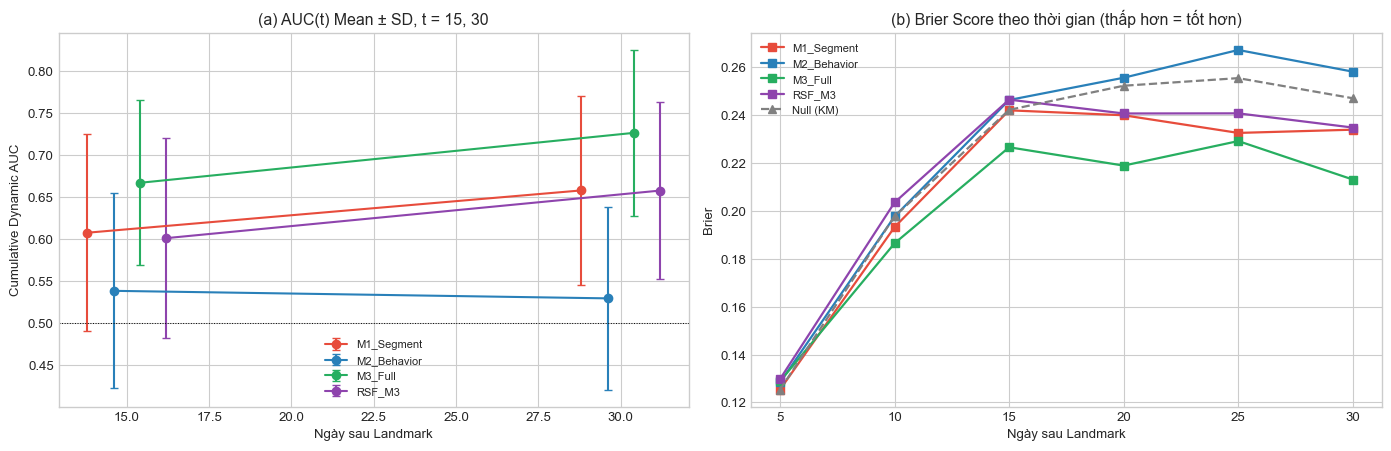


=== Ablation (Mean ± SD) ===


,C-index (Mean ± SD),AUC(30) Mean ± SD
Mô hình,,
M3_Full,0.620 ± 0.063,0.727 ± 0.099
M3_noIndia,0.588 ± 0.069,0.679 ± 0.111
M3_noScreens,0.563 ± 0.074,0.597 ± 0.098
M2_Behavior,0.517 ± 0.072,0.529 ± 0.109
M1_Segment,0.613 ± 0.072,0.658 ± 0.113
RSF_M3,0.581 ± 0.070,0.658 ± 0.106
RSF_All,0.590 ± 0.074,0.673 ± 0.122


In [6]:
# ---- Tổng hợp metric qua các fold: Mean ± SD 
def get_mean_sd(arr_2d):
    arr = np.asarray(arr_2d, dtype=float)
    mean = np.nanmean(arr, axis=0)
    sd = np.nanstd(arr, axis=0, ddof=1)
    n_valid = np.sum(np.isfinite(arr), axis=0)
    return mean, sd, n_valid

# ---- BẢNG HIỆU NĂNG (Mean ± SD qua các fold) ----
rows = []
for m in MODELS:
    c_arr = np.array(fold_metrics[m]['c'])
    c_mean = np.nanmean(c_arr)
    c_sd = np.nanstd(c_arr, ddof=1)

    auc_arr = np.array(fold_metrics[m]['auc'])
    auc_mean, auc_sd, auc_n = get_mean_sd(auc_arr)

    bs_arr = np.array(fold_metrics[m]['bs'])
    ibs_fold = np.array([
        trapezoid(row_bs, T_GRID) / (T_GRID[-1] - T_GRID[0])
        if not np.any(np.isnan(row_bs)) else np.nan
        for row_bs in bs_arr
    ])
    ibs_mean = np.nanmean(ibs_fold)

    row = {'Mô hình': m + (f' [{VIF_FLAG[m]}]' if VIF_FLAG.get(m) else ''),
           'C-index (Mean ± SD)': f'{c_mean:.4f} ± {c_sd:.4f}'}
    for j, t in enumerate(T_OK):
        row[f'AUC(t={int(t)}) Mean ± SD'] = f'{auc_mean[j]:.3f} ± {auc_sd[j]:.3f} (n={auc_n[j]})'
    row[f'IBS ({int(T_GRID[0])}-{int(T_GRID[-1])}d)'] = f'{ibs_mean:.4f}'
    rows.append(row)

tab_perf = pd.DataFrame(rows).set_index('Mô hình')

# IBS của Null để so sánh
ibs_null_folds = np.array([
    trapezoid(row_bs, T_GRID) / (T_GRID[-1] - T_GRID[0])
    if not np.any(np.isnan(row_bs)) else np.nan
    for row_bs in np.array(fold_metrics['Null']['bs'])
])
ibs_null_mean = np.nanmean(ibs_null_folds)

# Thêm cột IBS so với Null
for m in MODELS:
    ibs_val = float(tab_perf.loc[m + (f' [{VIF_FLAG[m]}]' if VIF_FLAG.get(m) else ''), f'IBS ({int(T_GRID[0])}-{int(T_GRID[-1])}d)'])
    tab_perf.loc[m + (f' [{VIF_FLAG[m]}]' if VIF_FLAG.get(m) else ''), 'IBS so với Null (%)'] = f'{(1 - ibs_val / ibs_null_mean) * 100:+.1f}'

print(f'=== HIỆU NĂNG MÔ HÌNH (5-fold CV x {N_REPEATS}; Mean ± SD qua các fold) ===')
display(tab_perf)
print(f'Null (KM fit trên train từng fold): IBS trung bình = {ibs_null_mean:.4f}')

# ---- BẢNG ΔC (chỉ mô tả, không p-value) ----
PAIRS = [
    ('M2_Behavior', 'M1_Segment'),
    ('M3_Full', 'M2_Behavior'),
    ('M3_Full', 'M3_noIndia'),
    ('M3_Full', 'M3_noScreens'),
    ('RSF_M3', 'M3_Full'),
    ('RSF_All', 'M3_Full')
]
dc_rows = []
for a, b_ in PAIRS:
    c_a = np.array(fold_metrics[a]['c'])
    c_b = np.array(fold_metrics[b_]['c'])
    mask = np.isfinite(c_a) & np.isfinite(c_b)
    diff = c_a[mask] - c_b[mask]
    dc_rows.append({
        'So sánh (A − B)': f'{a} − {b_}',
        'ΔC (Mean)': round(np.mean(diff), 4),
        'SD(ΔC)': round(np.std(diff, ddof=1), 4),
        'n_valid': int(mask.sum()),
        'Ghi chú': (
        f'Chênh lệch C-index trung bình (A − B) '
        f'= {np.mean(diff):+.3f}'
        )
    })
dc_tab = pd.DataFrame(dc_rows).set_index('So sánh (A − B)')
print('\n=== ΔC-index giữa các mô hình (chỉ thống kê mô tả, không kiểm định) ===')
display(dc_tab)

# ---- Hình: AUC(t) ± SD và Brier theo thời gian ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
show = ['M1_Segment', 'M2_Behavior', 'M3_Full', 'RSF_M3']
colors = {'M1_Segment': '#e74c3c', 'M2_Behavior': '#2980b9', 'M3_Full': '#27ae60', 'RSF_M3': '#8e44ad'}
for k, m in enumerate(show):
    auc_arr = np.array(fold_metrics[m]['auc'])
    auc_mean, auc_sd, _ = get_mean_sd(auc_arr)
    ax1.errorbar(T_OK + (k - 1.5) * 0.8, auc_mean, yerr=auc_sd,
                 marker='o', capsize=3, label=m, color=colors[m])
    bs_mean = np.nanmean(np.array(fold_metrics[m]['bs']), axis=0)
    ax2.plot(T_GRID, bs_mean, marker='s', label=m, color=colors[m], lw=1.6)

bs_null_mean = np.nanmean(np.array(fold_metrics['Null']['bs']), axis=0)
ax2.plot(T_GRID, bs_null_mean, marker='^', label='Null (KM)', color='gray', linestyle='--', lw=1.6)
ax1.axhline(.5, color='k', lw=.7, ls=':')
ax1.set_title(f'(a) AUC(t) Mean ± SD, t = {", ".join(str(int(t)) for t in T_OK)}')
ax1.set_xlabel('Ngày sau Landmark')
ax1.set_ylabel('Cumulative Dynamic AUC')
ax1.legend(fontsize=8)
ax2.set_title('(b) Brier Score theo thời gian (thấp hơn = tốt hơn)')
ax2.set_xlabel('Ngày sau Landmark')
ax2.set_ylabel('Brier')
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- Bảng ablation ----
ablation_models = ['M3_Full', 'M3_noIndia', 'M3_noScreens', 'M2_Behavior', 'M1_Segment', 'RSF_M3', 'RSF_All']
j30 = list(T_OK).index(30.0) if 30.0 in T_OK else 0
ablation_rows = []
for m in ablation_models:
    c_arr = np.array(fold_metrics[m]['c'])
    auc_arr = np.array(fold_metrics[m]['auc'])
    auc_mean, auc_sd, _ = get_mean_sd(auc_arr)
    ablation_rows.append({
        'Mô hình': m,
        'C-index (Mean ± SD)': f'{np.nanmean(c_arr):.3f} ± {np.nanstd(c_arr, ddof=1):.3f}',
        f'AUC(30) Mean ± SD': f'{auc_mean[j30]:.3f} ± {auc_sd[j30]:.3f}'
    })
print('\n=== Ablation (Mean ± SD) ===')
display(pd.DataFrame(ablation_rows).set_index('Mô hình'))

## 5.5. Calibration (illustrative, 3 nhóm rủi ro)

--- Calibration: Cox M2 (Hành vi) (t = 30 ngày sau Landmark; churn quan sát toàn mẫu = 0.586) ---


,n,dự đoán TB,quan sát (KM),CI thấp,CI cao
nhóm rủi ro,,,,,
1,43,0.459,0.480,0.332,0.653
2,43,0.583,0.760,0.617,0.881
3,43,0.688,0.504,0.356,0.673


    Tỷ lệ quan sát KHÔNG đơn điệu theo nhóm rủi ro dự đoán; sai lệch trung bình (dự đoán − quan sát) = -0.005. -> mô hình không xếp hạng rủi ro tốt ở mốc này; bảng chỉ mang tính minh họa.
--- Calibration: Cox M3 (Mở rộng) (t = 30 ngày sau Landmark; churn quan sát toàn mẫu = 0.586) ---


,n,dự đoán TB,quan sát (KM),CI thấp,CI cao
nhóm rủi ro,,,,,
1,43,0.385,0.350,0.223,0.519
2,43,0.593,0.663,0.509,0.810
3,43,0.786,0.773,0.618,0.898


    Tỷ lệ quan sát tăng đơn điệu theo nhóm rủi ro dự đoán; sai lệch trung bình (dự đoán − quan sát) = -0.007. 
--- Calibration: RSF (cùng biến M3) (t = 30 ngày sau Landmark; churn quan sát toàn mẫu = 0.586) ---


,n,dự đoán TB,quan sát (KM),CI thấp,CI cao
nhóm rủi ro,,,,,
1,43,0.425,0.460,0.318,0.629
2,43,0.589,0.564,0.416,0.723
3,43,0.764,0.734,0.580,0.867


    Tỷ lệ quan sát tăng đơn điệu theo nhóm rủi ro dự đoán; sai lệch trung bình (dự đoán − quan sát) = +0.006. 


,C-index (Mean ± SD),AUC(t=15) Mean ± SD,AUC(t=30) Mean ± SD,IBS so với Null (%)
Mô hình,,,,
M1_Segment,0.6125 ± 0.0719,0.608 ± 0.117 (n=50),0.658 ± 0.113 (n=50),+4.1
M2_Behavior,0.5171 ± 0.0720,0.538 ± 0.116 (n=50),0.529 ± 0.109 (n=50),-2.3
M2_Alt_Sessions [VI PHẠM VIF>5],0.5194 ± 0.0731,0.549 ± 0.112 (n=50),0.537 ± 0.112 (n=50),-2.4
M3_Full,0.6203 ± 0.0625,0.667 ± 0.098 (n=50),0.727 ± 0.099 (n=50),+9.0
M3_noIndia,0.5882 ± 0.0687,0.625 ± 0.095 (n=50),0.679 ± 0.111 (n=50),+5.3
M3_noScreens,0.5627 ± 0.0744,0.597 ± 0.113 (n=50),0.597 ± 0.098 (n=50),+2.2
RSF_M3,0.5805 ± 0.0703,0.601 ± 0.119 (n=50),0.658 ± 0.106 (n=50),+1.8
RSF_All,0.5904 ± 0.0735,0.590 ± 0.119 (n=50),0.673 ± 0.122 (n=50),+3.0


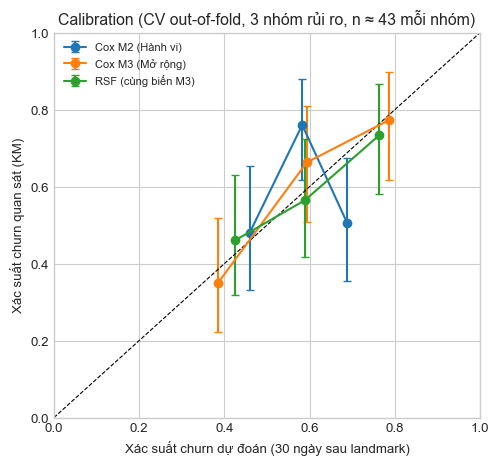

In [7]:
T_CAL = 30.0 if 30.0 in T_OK else float(T_OK.max())
J_CAL = int(np.where(T_GRID == T_CAL)[0][0])

def calib(model, bins=3):
    pred = 1 - oof_S[model][:, :, J_CAL].mean(axis=0)          # xác suất churn dự đoán tại T_CAL (TB qua các lần lặp)
    q = pd.qcut(pd.Series(pred).rank(method='first'), bins, labels=False)
    rows = []
    for g in range(bins):
        m = (q == g).values
        k = KaplanMeierFitter().fit(B.T_B[m], B.event[m])
        cif = k.confidence_interval_survival_function_
        s = float(k.predict(T_CAL)); i = cif.index.get_indexer([T_CAL], method='pad')[0]
        rows.append({'nhóm rủi ro': g + 1, 'n': int(m.sum()), 'dự đoán TB': pred[m].mean(), 'quan sát (KM)': 1 - s,
                     'CI thấp': 1 - cif.iloc[i, 1], 'CI cao': 1 - cif.iloc[i, 0]})
    return pd.DataFrame(rows).set_index('nhóm rủi ro')

cal_models = {'Cox M2 (Hành vi)': 'M2_Behavior', 'Cox M3 (Mở rộng)': 'M3_Full', 'RSF (cùng biến M3)': 'RSF_M3'}
cal = {label: calib(m_key) for label, m_key in cal_models.items()}
obs_all = 1 - float(KaplanMeierFitter().fit(B.T_B, B.event).predict(T_CAL))
for label, d in cal.items():
    mono = bool(d['quan sát (KM)'].is_monotonic_increasing)
    print(f'--- Calibration: {label} (t = {int(T_CAL)} ngày sau Landmark; churn quan sát toàn mẫu = {obs_all:.3f}) ---')
    display(d.round(3))
    print(f'    Tỷ lệ quan sát {"tăng đơn điệu" if mono else "KHÔNG đơn điệu"} theo nhóm rủi ro dự đoán; '
          f'sai lệch trung bình (dự đoán − quan sát) = {np.average(d["dự đoán TB"] - d["quan sát (KM)"], weights=d.n):+.3f}. '
          + ('' if mono else '-> mô hình không xếp hạng rủi ro tốt ở mốc này; bảng chỉ mang tính minh họa.'))
cols = [
    'C-index (Mean ± SD)',       
    'AUC(t=15) Mean ± SD',
    'AUC(t=30) Mean ± SD',
    'IBS so với Null (%)'
]

display(tab_perf[cols])
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, d in cal.items():
    ax.errorbar(d['dự đoán TB'], d['quan sát (KM)'], yerr=[d['quan sát (KM)'] - d['CI thấp'], d['CI cao'] - d['quan sát (KM)']], fmt='o-', capsize=3, label=label)
ax.plot([0, 1], [0, 1], 'k--', lw=.8); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel(f'Xác suất churn dự đoán ({int(T_CAL)} ngày sau landmark)'); ax.set_ylabel('Xác suất churn quan sát (KM)')
ax.set_title(f'Calibration (CV out-of-fold, 3 nhóm rủi ro, n ≈ {n // 3} mỗi nhóm)'); ax.legend(fontsize=8)

# 5.6 Xuất csv

In [8]:
OUT_PBI_DIR = os.environ.get('OUT_DIR', '../Datasets') 
os.makedirs(OUT_PBI_DIR, exist_ok=True)

## =========================================================
## 1. Xuất ml_model_performance.csv từ biến `tab_perf` (đã chạy ở Cell 8)
## =========================================================
df_pbi_perf = tab_perf.copy().reset_index()
df_pbi_perf['family'] = np.where(df_pbi_perf['Mô hình'].str.startswith('RSF'), 'Random Survival Forest', 'Cox PH')

# Trích xuất con số từ chuỗi định dạng văn bản
df_pbi_perf['c_index'] = df_pbi_perf['C-index (Mean ± SD)'].str.extract(r'^([\d\.]+)').astype(float)
df_pbi_perf['c_index_sd'] = df_pbi_perf['C-index (Mean ± SD)'].str.extract(r'± ([\d\.]+)').astype(float)
df_pbi_perf['auc_30'] = df_pbi_perf['AUC(t=30) Mean ± SD'].str.extract(r'^([\d\.]+)').astype(float)
df_pbi_perf['ibs_vs_null_pct'] = df_pbi_perf['IBS so với Null (%)'].str.replace('+', '').str.replace('%', '').astype(float)

# Đổi tên cho khớp Schema Power BI và xuất file
df_pbi_perf.rename(columns={'Mô hình': 'model'}, inplace=True)
cols_perf_export = ['model', 'c_index', 'c_index_sd', 'auc_30', 'ibs_vs_null_pct', 'family']
df_pbi_perf[cols_perf_export].to_csv(os.path.join(OUT_PBI_DIR, 'ml_model_performance.csv'), index=False)

# 2. Xuất ml_cox_hr.csv từ biến `tab_m1` và `tab_m3` (đã chạy ở Cell 6)
## =========================================================
# Dictionary để map tên biến tiếng Anh sang nhãn hiển thị Power BI
dict_var_names = {
    'log2_active_days': 'Số ngày hoạt động (log2)',
    'log2_level_starts': 'Số lượt bắt đầu level (log2)',
    'log2_screens': 'Số màn hình khác nhau (log2)',
    'android': 'Android',
    'india': 'Người dùng Ấn Độ',
    'plays_quickplay': 'Chơi quickplay',
    'engagement_segment_Low': 'Low (vs Very Low)',
    'engagement_segment_Moderate': 'Moderate (vs Very Low)',
    'engagement_segment_Highly Engaged': 'Highly Engaged (vs Very Low)',
    'engagement_segment_Dormant': 'Dormant (vs Very Low)'
}

# Gộp bảng M1 và M3
df_cox = pd.concat([tab_m1, tab_m3]).reset_index()
df_cox.rename(columns={'covariate': 'variable', 'HR': 'hr', 'CI thấp': 'ci_low', 'CI cao': 'ci_high', 'p': 'p_value'}, inplace=True)

# Gắn nhãn mô hình và tên biến
df_cox['model'] = df_cox['Mô hình'].apply(lambda x: 'M1 - Phân khúc' if 'M1' in x else 'M3 - Mở rộng')
df_cox['variable'] = df_cox['variable'].map(dict_var_names).fillna(df_cox['variable'])

# Xác định biến có ý nghĩa thống kê (xử lý chuỗi '<0.001')
df_cox['p_value_num'] = df_cox['p_value'].replace('<0.001', '0.0').astype(float)
df_cox['significant'] = (df_cox['p_value_num'] < 0.05).astype(int)

# Chọn cột và xuất file
cols_cox_export = ['model', 'variable', 'hr', 'ci_low', 'ci_high', 'p_value', 'significant']
df_cox[cols_cox_export].to_csv(os.path.join(OUT_PBI_DIR, 'ml_cox_hr.csv'), index=False)


## 3) Kaplan-Meier (có delayed entry + CI Greenwood)
def km_table(df, group, dimension, tcol='T', entry_col='entry', tmax=90):
    d = df.dropna(subset=[tcol])
    T = d[tcol].astype(int).values; E = d.event.astype(int).values
    en = d[entry_col].astype(int).values if entry_col else np.zeros(len(d), int)
    S, var_sum, rows = 1.0, 0.0, []
    for t in range(1, tmax + 1):
        at_risk = int(((en < t) & (T >= t)).sum())
        ev = int(((T == t) & (E == 1)).sum())
        if at_risk == 0:
            continue          
        S *= (1 - ev / at_risk)
        if at_risk > ev and ev > 0:
            var_sum += ev / (at_risk * (at_risk - ev))
        se = S * np.sqrt(var_sum)
        rows.append(dict(dimension=dimension, grp=group, t=t, survival=S,
                         ci_low=max(0, S - 1.96 * se), ci_high=min(1, S + 1.96 * se),
                         n_at_risk=at_risk, n_events=ev, reliable=int(at_risk >= MIN_AT_RISK)))
    return pd.DataFrame(rows)
 
A2 = A.copy()
A2['country_group'] = np.where(A2['country'] == 'India', 'India',
                      np.where(A2['country'] == 'United States', 'United States', 'Other'))
A2['platform'] = A2['platform'].map({'IOS': 'iOS', 'ANDROID': 'Android'})
A2['device_category'] = A2['device_category'].str.capitalize()
V = A2[A2.verified_new == 1]
 
parts = [
    km_table(V, 'Cài mới - verified', 'Nhóm người dùng'),
    km_table(A2[~A2.is_new], 'Cài cũ (delayed entry)', 'Nhóm người dùng'),
]
for col, dimname in [('platform', 'Nền tảng'), ('country_group', 'Quốc gia'), ('device_category', 'Thiết bị')]:
    for val, sub in V.groupby(col):
        parts.append(km_table(sub, val, dimname))
for val, sub in B.groupby('engagement_segment'):
    parts.append(km_table(sub, val, 'Phân khúc (Nhóm B, tính từ Landmark)', tcol='T_B', entry_col=None, tmax=90))
km_all = pd.concat(parts, ignore_index=True)
km_all.to_csv(os.path.join(OUT_PBI_DIR, 'km_curve.csv'), index=False)


## 4) Hazard theo khoảng thời gian (Đồng bộ với Cell 4)
def export_hazard(df, label, entry=False):
    # Gọi lại hàm từ Cell 4
    out = interval_hazard(df, entry=entry).reset_index()
    out['population'] = label
    
    # Đổi tên cột sang tiếng Anh để nạp vào Power BI
    out = out.rename(columns={
        'Khoảng (ngày)': 'interval_label',
        'Độ dài (ngày)': 'interval_days',
        'Người ở đầu khoảng': 'n_at_start',
        'Người-ngày (Person-days)': 'person_days',
        'Sự kiện': 'n_events',
        'Hazard rate (ngày⁻¹)': 'hazard_per_day',
        'CI thấp': 'ci_low',
        'CI cao': 'ci_high'
    })
    
    # Tạo thêm cột thứ tự khoảng để Power BI sắp xếp đúng
    out['interval_order'] = range(1, len(out) + 1)
    
    return out[['population', 'interval_label', 'interval_order', 'interval_days', 
                'n_at_start', 'person_days', 'n_events', 'hazard_per_day', 'ci_low', 'ci_high']]

# V được định nghĩa ở trên là cohort verified, A2 là toàn bộ nhóm A
haz = pd.concat([
    export_hazard(V, 'Cài mới - verified', entry=False),
    export_hazard(A2, 'Nhóm A (gồm cài cũ, delayed entry)', entry=True)
], ignore_index=True)

haz.to_csv(os.path.join(OUT_PBI_DIR, 'hazard_interval.csv'), index=False)
